# Joelho, malha, acústica do tampão e arrasto espúrio

A sensibilidade do ciclo ao tratamento do joelho e da malha, o modo acústico do tampão de líquido e a viscosidade artificial, a reconstrução de α nas faces e o arrasto espúrio da fase virtual.

Issues ilustradas (índice em [docs/issues/INDEX.md](../../docs/issues/INDEX.md)):
- [006](../../docs/issues/006-arrasto-espurio-fase-virtual.md)
- [007](../../docs/issues/007-viscosidade-artificial.md)
- [008](../../docs/issues/008-joelho-em-arco.md)
- [009](../../docs/issues/009-malha-graduada.md)
- [010](../../docs/issues/010-reconstrucao-muscl.md)
- [011](../../docs/issues/011-compressibilidade-artificial.md)

*Nenhuma simulação corre aqui: as corridas vêm de `notebooks/data` (dados históricos, 2026-10)
e dos lotes `batches/*.json` (`mfsim batch`); o notebook só lê e desenha.*

In [1]:
import numpy as np, matplotlib.pyplot as plt, os, json, warnings

warnings.filterwarnings("ignore")
from mfsim.fluid import Fluid
from mfsim.runs import find_run, load_run

fluid = Fluid(rhoL0=900.0, rhoG0=1.2, muL=2e-3, muG=1.8e-5, gammaL=100.0, gammaG=1.05, P0=1e5, sigma=0.05)
D = 0.05
A = np.pi * D**2 / 4
P_out = 4.0
qL = 0.3 * 900 * A
qG = 0.1 * fluid.rhoG((P_out + 1) * 1e5) * A


def datafile(fname):
    """Caminho de uma corrida gravada (notebooks/data ou runs/), ou None se não existir."""
    try:
        return find_run(fname)
    except FileNotFoundError:
        print("trajetória não encontrada:", fname)
        return None


def blowdowns(T_, P_in, min_gap=200.0):
    """Instantes dos blowdowns: mínimos locais da pressão na entrada abaixo de 30 % da
    faixa (separados por pelo menos min_gap s; um blowdown tem mínimos secundários nos
    100 s seguintes). Mais robusto do que contar picos de vazão."""
    lvl = P_in.min() + 0.3 * (P_in.max() - P_in.min())
    low = P_in < lvl
    out = []
    i = 0
    while i < T_.size:
        if low[i]:
            j = i
            while j < T_.size and low[j]:
                j += 1
            k = i + int(np.argmin(P_in[i:j]))
            if not out or T_[k] - out[-1] > min_gap:
                out.append(T_[k])
            i = j
        else:
            i += 1
    return np.array(out)


def cycle_stats(T_, P_in, q_out):
    """(número de blowdowns, período médio entre blowdowns [s], pico máximo de líquido após t = 100 s)."""
    tb = blowdowns(T_, P_in)
    per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
    return tb.size, per, float(q_out[T_ > 100].max())


def load_blocked_run(f):
    """Corrida gravada (partida bloqueada ou linha fechada) pelo carregador único
    `mfsim.runs.load_run` (reconstrói o caso do `meta` com os defaults deste notebook, ou de
    `case_json` nas corridas novas) e os balanços de massa; era uma cópia desta lógica."""
    r = load_run(f)
    return dict(
        meta=r.meta,
        case=r.case,
        model=r.model,
        res=r.res,
        T=r.T,
        p=r.pipe(0),
        ib=r.ib,  # célula no início do joelho
        balL=r.balance("L"),
        balG=r.balance("G"),
        acc=r.acc,  # integral BDF-consistente dos fluxos de contorno
        p_last=r.p_last,  # duto que termina no separador (rede: o último)
        aG_riser_base=r.aG_riser_base(),
    )

## Corridas de referência com joelho anguloso (partida bloqueada, malha grossa, 3000 s)

In [2]:
runs = {}
for tag, fname in (
    ("primitivas", "severe_slug_blocked_primitive.npz"),
    ("conservativo", "severe_slug_blocked_conservative.npz"),
):
    f = datafile(fname)
    if f is None:
        print("trajetória não encontrada:", f)
        continue
    runs[tag] = load_blocked_run(f)
    mb = runs[tag]["meta"]
    print(f"{tag:13s}: {mb['n_steps']} passos, {mb['n_rejected']} rejeitados, {mb['cpu']/60:.0f} min de CPU")

primitivas   : 91783 passos, 24105 rejeitados, 18 min de CPU


conservativo : 132679 passos, 39681 rejeitados, 25 min de CPU


## Joelho curvo e transição suave dos fechamentos por ângulo

Na geometria acima a inclinação passa de −3° a 90° entre duas células vizinhas e
o fechamento muda de forma abrupta (estratificado na linha, bolhas no riser,
chave dura em |θ| > 45°). Dois ingredientes removem essa descontinuidade espacial:

1. **joelho em arco** (`elbow_radius`, `n_elbow`): o trecho descendente e o riser
   são ligados por um arco de raio R tangente a ambos, discretizado em elementos
   cujos ângulos crescem gradualmente de −3° a 90° (a inclinação já era um campo
   por elemento; só o traçado muda);
2. **mistura por ângulo** (`vertical_blend`, em graus): o peso do padrão vertical
   é uma rampa C1 (smoothstep) entre 45° − Δ e 45° + Δ, e os fechamentos são
   somados com pesos (1 − w) e w. Sem o arco a mistura só atua na face do joelho
   (θ ≈ 43.5°) e **piora** a convergência (face com metade de cada fechamento entre
   duas células "puras"); com o arco ela reduz os passos em ~13 % na fase inicial.

Abaixo, o mesmo caso (partida bloqueada, malha grossa, 3000 s) com R = 5 m, 4
elementos no arco e Δ = 20°, nas duas formulações, comparado com o joelho
anguloso. Os ciclos são contados pelos *blowdowns* (mínimos da pressão na
entrada), porque um blowdown pode ter mais de um pico de vazão.

In [3]:
runs_arc = {}
for tag, fname in (
    ("primitivas", "severe_slug_blocked_primitive_arc.npz"),
    ("conservativo", "severe_slug_blocked_conservative_arc.npz"),
):
    f = datafile(fname)
    if f is None:
        print("trajetória não encontrada:", f)
        continue
    runs_arc[tag] = load_blocked_run(f)
    mb = runs_arc[tag]["meta"]
    print(
        f"{tag:13s} (arco R = {mb['elbow_radius']} m, {mb['n_elbow']} elementos, Δ = {mb['vertical_blend']}°): "
        f"{mb['n_steps']} passos, {mb['n_rejected']} rejeitados, {mb['cpu']/60:.0f} min de CPU"
    )

primitivas    (arco R = 5.0 m, 4 elementos, Δ = 20.0°): 128021 passos, 31494 rejeitados, 24 min de CPU


conservativo  (arco R = 5.0 m, 4 elementos, Δ = 20.0°): 112474 passos, 29359 rejeitados, 22 min de CPU


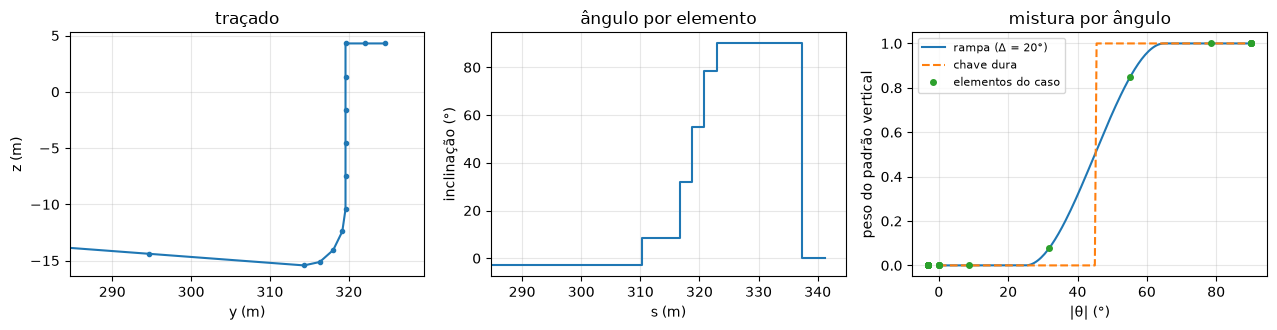

In [4]:
if runs_arc:
    r = next(iter(runs_arc.values()))
    case_a = r["case"]
    model_a = r["model"]
    from mfsim.geometry import pipe_mesh

    mesh_a = pipe_mesh(case_a.pipes[0].x, case_a.pipes[0].y, case_a.pipes[0].z, case_a.pipes[0].n_elements)
    th_deg = np.rad2deg(mesh_a["theta"])
    s_mid = 0.5 * (mesh_a["s"][1:] + mesh_a["s"][:-1])
    w = model_a.pipes[0].model.vertical_weight(mesh_a["theta"])
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    axes[0].plot(mesh_a["xyz"][:, 1], mesh_a["xyz"][:, 2], ".-")
    axes[0].set_xlabel("y (m)")
    axes[0].set_ylabel("z (m)")
    axes[0].set_title("traçado")
    axes[0].set_xlim(mesh_a["xyz"][-1, 1] - 40, mesh_a["xyz"][-1, 1] + 5)
    axes[1].step(s_mid, th_deg, where="mid")
    axes[1].set_xlabel("s (m)")
    axes[1].set_ylabel("inclinação (°)")
    axes[1].set_title("ângulo por elemento")
    axes[1].set_xlim(case_a.meta["s_elbow0"] - 30, case_a.meta["s_elbow0"] + 30)
    ang = np.linspace(0, 90, 181)
    axes[2].plot(ang, model_a.pipes[0].model.vertical_weight(np.deg2rad(ang)), label="rampa (Δ = 20°)")
    axes[2].plot(ang, (ang > 45).astype(float), "--", label="chave dura")
    axes[2].plot(th_deg, w, "o", ms=4, label="elementos do caso")
    axes[2].set_xlabel("|θ| (°)")
    axes[2].set_ylabel("peso do padrão vertical")
    axes[2].legend(fontsize=8)
    axes[2].set_title("mistura por ângulo")
    for ax in axes:
        ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

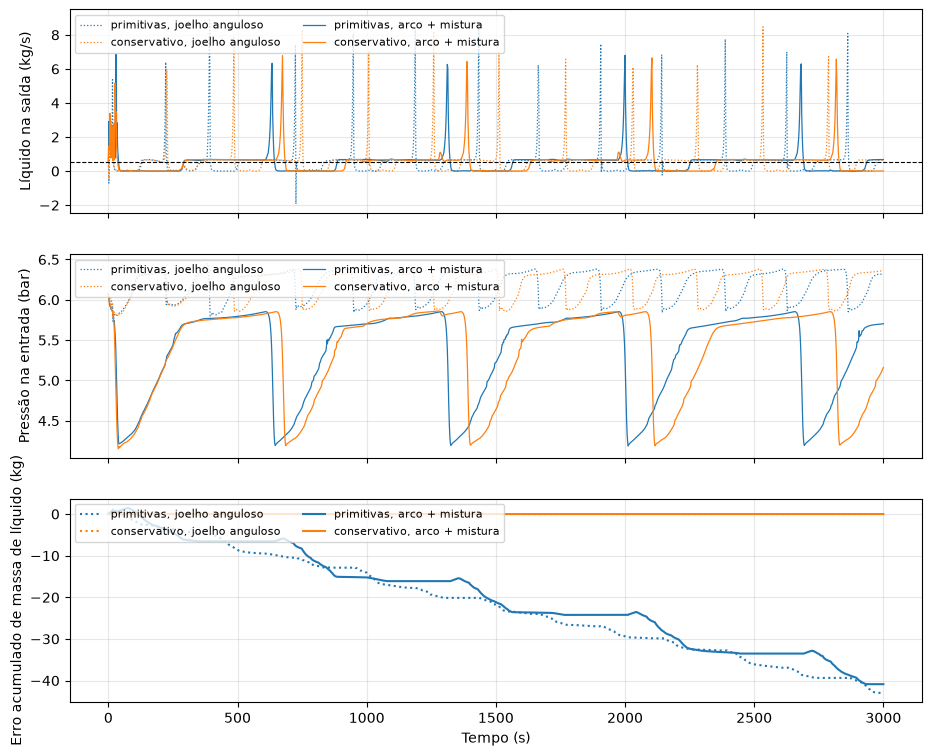

primitivas    joelho anguloso:   91783 passos | 12 blowdowns, período ≈ 259 s, pico máximo 8.9 kg/s, P_in 5.73–6.45 bar | erro de massa de líquido -4.30e+01 kg
conservativo  joelho anguloso:  132679 passos | 12 blowdowns, período ≈ 254 s, pico máximo 8.5 kg/s, P_in 5.78–6.39 bar | erro de massa de líquido -1.14e-05 kg
primitivas    arco + mistura :  128021 passos | 5 blowdowns, período ≈ 662 s, pico máximo 6.8 kg/s, P_in 4.19–6.06 bar | erro de massa de líquido -4.09e+01 kg
conservativo  arco + mistura :  112474 passos | 5 blowdowns, período ≈ 698 s, pico máximo 6.8 kg/s, P_in 4.15–6.06 bar | erro de massa de líquido -1.01e-05 kg


In [5]:
if runs_arc:
    fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
    for k, (tag, r) in enumerate(list(runs.items()) + list(runs_arc.items())):
        arc = r["meta"].get("n_elbow", 0) > 0
        lab = f"{tag}, {'arco + mistura' if arc else 'joelho anguloso'}"
        ls = "-" if arc else ":"
        T_, p_, ib_ = r["T"], r["p"], r["ib"]
        axes[0].plot(T_, p_["out"]["qL"][-1], ls, color=f"C{k % 2}", lw=0.9, label=lab)
        axes[1].plot(T_, p_["out"]["P_bar"][1], ls, color=f"C{k % 2}", lw=0.9, label=lab)
        massL, netL, _ = r["balL"]
        if r["acc"] is not None:
            axes[2].plot(T_, massL - massL[0] - r["acc"][0], ls, color=f"C{k % 2}", label=lab)
    axes[0].axhline(qL, color="k", ls="--", lw=0.8)
    axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na entrada (bar)")
    axes[2].set_ylabel("Erro acumulado de massa de líquido (kg)")
    axes[2].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="upper left", ncol=2)
    plt.show()
    for tag, r in list(runs.items()) + list(runs_arc.items()):
        arc = r["meta"].get("n_elbow", 0) > 0
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        massL, _, _ = r["balL"]
        eL = (massL[-1] - massL[0] - r["acc"][0, -1]) if r["acc"] is not None else np.nan
        print(
            f"{tag:13s} {'arco + mistura ' if arc else 'joelho anguloso'}: {r['meta']['n_steps']:7d} passos | {nb_} blowdowns, período ≈ {per:.0f} s, "
            f"pico máximo {qmax:.1f} kg/s, P_in {r['p']['out']['P_bar'][1].min():.2f}–{r['p']['out']['P_bar'][1].max():.2f} bar | erro de massa de líquido {eL:+.2e} kg"
        )

### Fração de gás junto ao joelho
Perfis em instantes de um ciclo (formulação conservativa): com o arco a frente
de líquido e a entrada de gás no riser são resolvidas em células de ângulo
intermediário em vez de saltarem entre a última célula da linha e a primeira do riser.

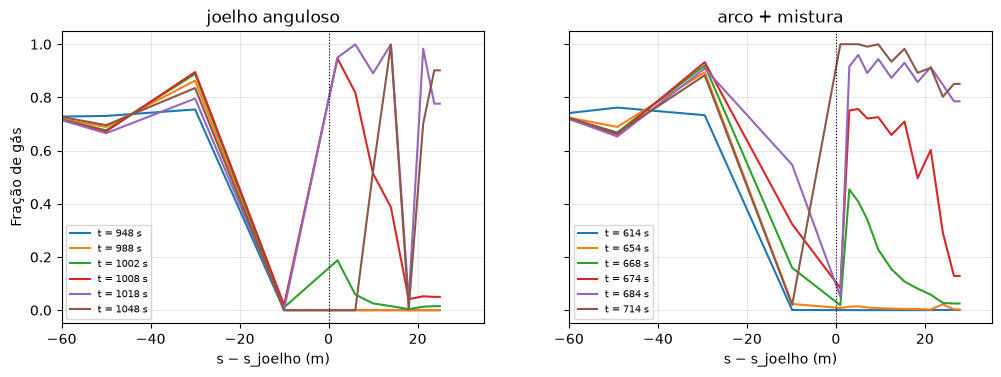

In [6]:
if "conservativo" in runs_arc and "conservativo" in runs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
    for ax, (lab, r) in zip(
        axes, (("joelho anguloso", runs["conservativo"]), ("arco + mistura", runs_arc["conservativo"]))
    ):
        T_, p_ = r["T"], r["p"]
        x_ = p_["x"]
        s0 = r["case"].meta["s_elbow0"]
        q_ = p_["out"]["qL"][-1]
        pk = [i for i in range(1, T_.size - 1) if q_[i] > 2.0 and q_[i] >= q_[i - 1] and q_[i] > q_[i + 1]]
        i0 = pk[5] if len(pk) > 6 else T_.size // 2
        for dt_ in (-60, -20, -5, 0, 10, 40):
            it = min(max(i0 + dt_ // 2, 0), T_.size - 1)
            ax.plot(x_ - s0, p_["out"]["alphaG"][:, it], label=f"t = {T_[it]:.0f} s")
        ax.axvline(0, color="k", lw=0.8, ls=":")
        ax.set_xlim(-60, 35)
        ax.set_xlabel("s − s_joelho (m)")
        ax.set_title(lab)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    axes[0].set_ylabel("Fração de gás")
    plt.show()

## Malha não uniforme (refinamento no joelho)

Os maiores gradientes estão no "pescoço": fim do trecho descendente, arco e base
do riser (frente de líquido, entrada do gás no riser). `pipe_mesh` aceita, por
trecho, a razão entre o último e o primeiro elemento (`grading`, progressão
geométrica): no trecho descendente `grading_down` < 1 refina para o joelho e no
riser `grading_riser` > 1 refina a base. O esquema de volumes finitos usa as
distâncias entre centros de células (`dx_faces`), por isso não precisa de
alteração. Quatro malhas, todas com arco (R = 5 m, 4 elementos) e mistura por
ângulo (Δ = 20°), formulação conservativa, partida bloqueada, 3000 s:

| malha | células | descendente (m) | riser (m) |
|---|---|---|---|
| uniforme 15/5 | 28 | 19.6 | 2.95 |
| graduada 15/5 (0.25 / 3) | 28 | 35.9 → 9.0 | 1.58 → 4.74 |
| uniforme 30/10 | 48 | 9.8 | 1.47 |
| graduada 30/10 (0.25 / 3) | 48 | 18.1 → 4.5 | 0.80 → 2.40 |

A pergunta é se, a custo igual (mesmo número de células), a malha graduada se
aproxima mais da malha fina — e se a fina graduada muda o resultado da fina
uniforme (indicador de convergência de malha).

**Modo acústico do tampão de líquido.** A primeira tentativa com a malha fina
graduada (0.8 m na base do riser) rastejou com passos de 1 ms. O diagnóstico com
saída a cada 5 ms mostrou um modo acústico do tampão de líquido que se forma na
base do riser depois de cada *blowdown* (≈ 8 m de líquido entre o bolsão da linha
e o gás do riser): vazão de líquido e pressão oscilando a ≈ 16–20 Hz = c/2L, com
c = 258 m/s (expoente politrópico 100). O gradiente de pressão centrado não
amortece acústica, o BDF2 quase não dissipa e o controlador de passo resolve a
oscilação. Remédio numérico adotado: viscosidade artificial linear ν = 0.01·c·h
nas equações de momento (`art_visc`; some com h → 0, taxa ν·k² desprezível para
ondas longas), que reduz o custo em todas as malhas; a regularização hiperbólica
da seção seguinte (`low_void_regime` + `interfacial_pressure`) é mostrada como
quinta trajetória na malha grossa. As trajetórias desta seção têm `art_visc`; o
custo sem ele (malha grossa 112 mil passos, graduada 166 mil, fina 262 mil) está
no README.

In [7]:
runs_mesh = {}
for tag, fname in (
    ("uniforme 15/5", "severe_slug_blocked_conservative_arc_av.npz"),
    ("graduada 15/5", "severe_slug_blocked_conservative_arc_graded_av.npz"),
    ("uniforme 30/10", "severe_slug_blocked_conservative_arc_fine_av.npz"),
    ("graduada 30/10", "severe_slug_blocked_conservative_arc_fine_graded_av.npz"),
    ("uniforme 15/5 + regularização", "severe_slug_blocked_conservative_arc_av_reg.npz"),
):
    f = datafile(fname)
    if f is None:
        print("trajetória não encontrada:", f)
        continue
    runs_mesh[tag] = load_blocked_run(f)

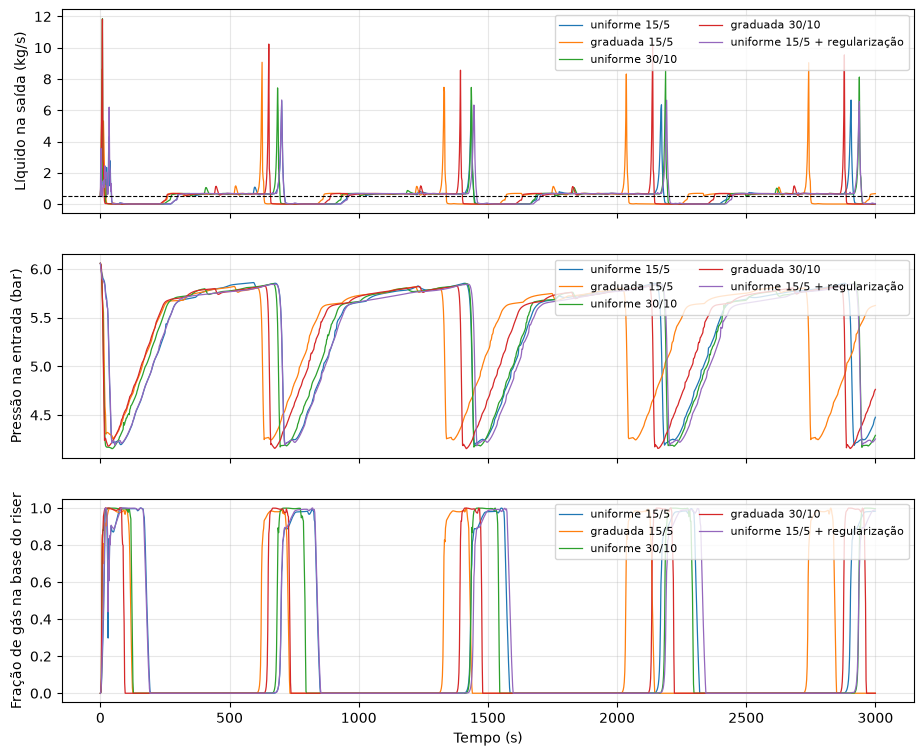

malha              passos     CPU blowdowns  período  pico máx   P_in (bar)  erro massa L
uniforme 15/5       85653    20 min         5    710 s    6.7 kg/s  4.19–5.86     -5.1e-06 kg
graduada 15/5      145286    35 min         5    682 s    9.1 kg/s  4.24–5.82     -2.0e-04 kg
uniforme 30/10     201553    58 min         5    726 s    8.6 kg/s  4.17–5.85     -9.5e-06 kg
graduada 30/10     302648    83 min         5    718 s   10.2 kg/s  4.15–5.83     -1.3e-05 kg
uniforme 15/5 + regularização    85418    22 min         5    724 s    6.7 kg/s  4.19–5.84     -5.3e-06 kg


In [8]:
if runs_mesh:
    fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
    for k, (tag, r) in enumerate(runs_mesh.items()):
        T_, p_ = r["T"], r["p"]
        axes[0].plot(T_, p_["out"]["qL"][-1], lw=0.9, label=tag)
        axes[1].plot(T_, p_["out"]["P_bar"][1], lw=0.9, label=tag)
        axes[2].plot(T_, p_["out"]["alphaG"][r["ib"] + r["meta"]["n_elbow"] + 1], lw=0.9, label=tag)
    axes[0].axhline(qL, color="k", ls="--", lw=0.8)
    axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na entrada (bar)")
    axes[2].set_ylabel("Fração de gás na base do riser")
    axes[2].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="upper right", ncol=2)
    plt.show()
    print(
        f"{'malha':16s} {'passos':>8s} {'CPU':>7s} {'blowdowns':>9s} {'período':>8s} {'pico máx':>9s} {'P_in (bar)':>12s} {'erro massa L':>13s}"
    )
    for tag, r in runs_mesh.items():
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        massL, _, _ = r["balL"]
        eL = (massL[-1] - massL[0] - r["acc"][0, -1]) if r["acc"] is not None else np.nan
        P1 = r["p"]["out"]["P_bar"][1][T_ > 100]
        print(
            f"{tag:16s} {r['meta']['n_steps']:8d} {r['meta']['cpu']/60:5.0f} min {nb_:9d} {per:6.0f} s {qmax:6.1f} kg/s {P1.min():5.2f}–{P1.max():4.2f} {eL:+12.1e} kg"
        )

### Perfis junto ao joelho num instante do blowdown
Mesmo instante relativo ao pico de líquido (≈ 6 s antes do pico), em cada malha.

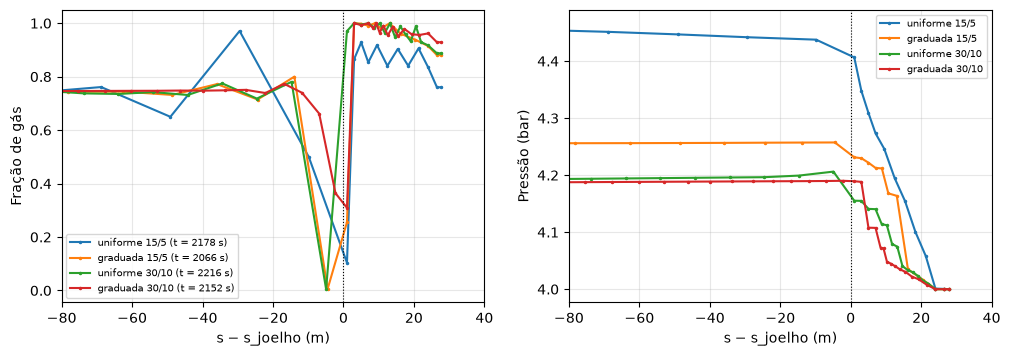

In [9]:
if runs_mesh:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for k, (tag, r) in enumerate(runs_mesh.items()):
        if "regulariza" in tag:
            continue
        T_, p_ = r["T"], r["p"]
        x_ = p_["x"]
        s0 = r["case"].meta["s_elbow0"]
        tb = blowdowns(T_, p_["out"]["P_bar"][1])
        tb = tb[tb > 600]
        if tb.size == 0:
            continue
        it = max(int(np.argmin(np.abs(T_ - tb[len(tb) // 2]))) - 3, 0)
        axes[0].plot(x_ - s0, p_["out"]["alphaG"][:, it], ".-", ms=3, label=f"{tag} (t = {T_[it]:.0f} s)")
        axes[1].plot(x_ - s0, p_["out"]["P_bar"][:, it], ".-", ms=3, label=tag)
    for ax, yl in zip(axes, ("Fração de gás", "Pressão (bar)")):
        ax.axvline(0, color="k", lw=0.8, ls=":")
        ax.set_xlim(-80, 40)
        ax.set_xlabel("s − s_joelho (m)")
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    plt.show()

## Reconstrução de α nas faces e o arrasto espúrio da fase virtual

Dois temas levantados na lista de pendências. **(1) Reconstrução MUSCL/TVD da
fração de área nas faces** (`alpha_face="muscl"`: declive minmod a partir da
célula doadora, numpy e JAX) para ganhar nitidez da frente sem refinar a malha.
No esquema escalonado as vazões das faces são estados e os fluxos de massa são
essas vazões (limitadas pela célula doadora); a fração nas faces só entra na
equação de momento (gradiente de pressão, gravidade, velocidades). Resultado na
malha grossa: ciclo igual (intervalo 775 s contra 765 s, P_in 4.12–6.04) e a
largura mediana da frente de gás no riser (transição 0.1–0.9 de αG) fica em 2.9 m
nas duas variantes, contra 1.7 m na malha fina: a difusão da frente vem da
dinâmica do momento (velocidade doadora de 1ª ordem, relaxação da fase ausente,
limitador), não da interpolação de α; o MUSCL em α não é uma alavanca de nitidez.

**(2) Excitação do modo acústico do tampão.** Experimento controlado: coluna de
20 m (20 células) entre duas extremidades, com (B) líquido monofásico, (A') o modelo
a dois fluidos com a coluna cheia de líquido (αG = 0) e (A) um tampão de 12 m entre
dois bolsões de gás (αG = 0.7). Com um degrau de pressão entre pressões fixas, a
coluna monofásica acelera livremente (3.6 kg/s em 3 s) e a coluna do modelo a dois
fluidos com fechamento estratificado **trava em 0.49 kg/s**: a decomposição do
balanço de momento mostra GammaL = 1.96 N/m contra 0.05 N/m de atrito de parede. É
a **força interfacial com a camada de gás virtual** (αG cortado em 1e−3) que a
relaxação da fase ausente mantém parada (o alvo de vazão usa a fração REAL, nula):
a 0.27 m/s o estratificado exerce 40× o atrito de parede, a 1 m/s 58× (anular 8–10×;
bolhas e intermitente nada). Com o gás virtual acompanhando o líquido (vG = vL) todos
os fechamentos reproduzem o monofásico. Daí a opção `relax_target="noslip"`
(alvo sem escorregamento com a fração da célula doadora com piso em `alpha_min`, nas
duas fases; só no modo conservativo, onde o limitador de fluxo impede que a vazão
virtual drene massa): a coluna volta a 3.65 kg/s e o decaimento do modo acústico
fechado passa de 1.33 para 0.63 1/s (monofásico 0.32). Uma primeira versão usou a
fração média da face em vez da doadora e fazia o severe slug rastejar: numa face
entre uma célula cheia de gás e outra com 13 % de gás o filme de 1 % era arrastado
como se fosse 44 % do tubo, à velocidade do gás do blowdown. Conclusão para a pergunta original: as células cheias de líquido do
modelo a dois fluidos não excitam o modo do tampão; são **mais amortecidas** do que o
monofásico por um arrasto espúrio, que liga e desliga nas células onde a fração
cruza a banda da relaxação. No severe slug de referência (tabela abaixo) a variante
`noslip` (ver tabela) custa o mesmo, mantém o ciclo (intervalo 749 s contra 765)
e baixa a pressão máxima de entrada de 6.00 para 5.92 bar e os picos de 7.9 para
7.1 kg/s. É a variante fisicamente consistente; os resultados anteriores devem
ser lidos com essa ressalva.

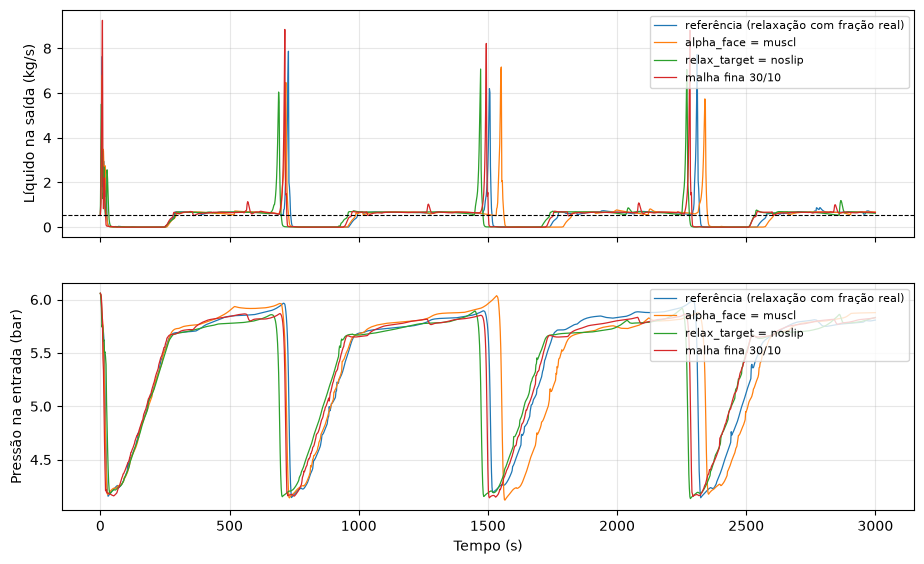

configuração                               passos    CPU blowdowns intervalo  pico máx   P_in (bar) frente 0.1-0.9
referência (relaxação com fração real)      25923    50 s         4     765 s    7.9 kg/s  4.14–6.00        2.9 m
alpha_face = muscl                          24788    48 s         4     775 s    7.2 kg/s  4.12–6.04        2.9 m
relax_target = noslip                       25228    47 s         4     749 s    7.1 kg/s  4.14–5.92        2.9 m
malha fina 30/10                            39033   105 s         4     747 s    8.8 kg/s  4.14–5.87        1.7 m


In [10]:
runs_ns = {}
for tag, fname in (
    ("referência (relaxação com fração real)", "severe_slug_blocked_conservative_arc_tol.npz"),
    ("alpha_face = muscl", "severe_slug_blocked_conservative_arc_tol_muscl.npz"),
    ("relax_target = noslip", "severe_slug_blocked_conservative_arc_tol_noslip.npz"),
    ("malha fina 30/10", "severe_slug_blocked_conservative_arc_fine_fast1_jax.npz"),
):
    f = datafile(fname)
    if f is None:
        print("trajetória não encontrada:", f)
        continue
    runs_ns[tag] = load_blocked_run(f)


def front_width(r):
    """Largura mediana (m) da transição 0.1-0.9 de alphaG no riser nos instantes com gás no riser."""
    x_ = r["p"]["x"]
    aG_ = r["p"]["out"]["alphaG"]
    ib_ = r["ib"]
    w = []
    for it in range(r["T"].size):
        seg = aG_[ib_:, it]
        xs = x_[ib_:]
        if seg.max() > 0.5 and seg.min() < 0.05:
            j1 = np.argmax(seg > 0.1)
            j9 = np.argmax(seg > 0.9) if (seg > 0.9).any() else len(seg) - 1
            if j9 > j1:
                w.append(xs[j9] - xs[j1])
    return float(np.median(w)) if w else np.nan


if runs_ns:
    fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
    for tag, r in runs_ns.items():
        axes[0].plot(r["T"], r["p"]["out"]["qL"][-1], lw=0.9, label=tag)
        axes[1].plot(r["T"], r["p"]["out"]["P_bar"][1], lw=0.9, label=tag)
    axes[0].axhline(qL, color="k", ls="--", lw=0.8)
    axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na entrada (bar)")
    axes[1].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="upper right")
    plt.show()
    print(
        f"{'configuração':40s} {'passos':>8s} {'CPU':>6s} {'blowdowns':>9s} {'intervalo':>9s} {'pico máx':>9s} {'P_in (bar)':>12s} {'frente 0.1-0.9':>14s}"
    )
    for tag, r in runs_ns.items():
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        P1 = r["p"]["out"]["P_bar"][1][T_ > 100]
        print(
            f"{tag:40s} {r['meta']['n_steps']:8d} {r['meta']['cpu']:5.0f} s {nb_:9d} {per:7.0f} s {qmax:6.1f} kg/s {P1.min():5.2f}–{P1.max():4.2f} {front_width(r):10.1f} m"
        )

### Experimento da coluna de líquido (corridas `runs/issues/column_*`, gerador `generators/column.py`)
Coluna de 20 m entre duas extremidades: B = líquido monofásico; Ap = modelo a dois fluidos cheia de
líquido. Degrau de 0.2 bar entre pressões fixas (esquerda) ou extremidades fechadas com o degrau no
meio (modo acústico c/2L, direita), com a relaxação da fase ausente no alvo de fração real (`raw`)
e sem escorregamento (`noslip`).

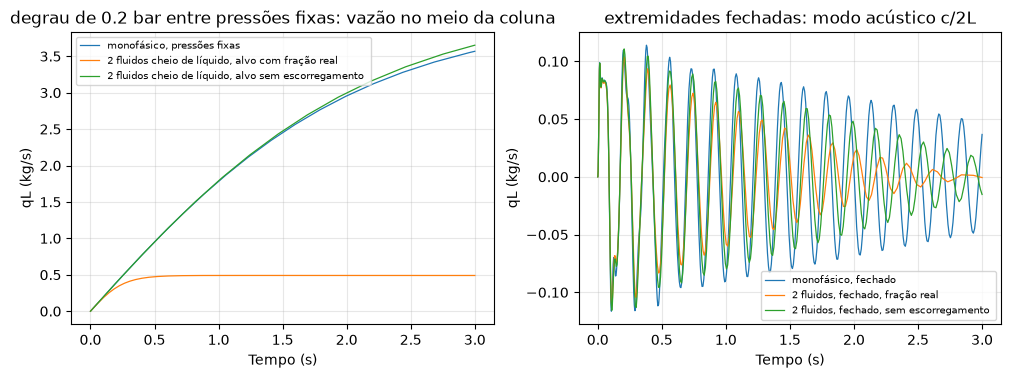

caso                                                 passos  q final  f (Hz)  decaimento (1/s)
monofásico, pressões fixas                               26    3.568     nan               nan
2 fluidos cheio de líquido, alvo com fração real         27    0.490     nan               nan
2 fluidos cheio de líquido, alvo sem escorregamento      23    3.651     nan               nan
monofásico, fechado                                     406    0.037    5.56              0.31
2 fluidos, fechado, fração real                         240   -0.001    5.56              1.33
2 fluidos, fechado, sem escorregamento                  294   -0.015    5.56              0.63


In [11]:
from scipy.signal import find_peaks


def q_mid(r):
    """Vazão de líquido na face central da coluna ao longo do tempo (estados gravados a cada 1 ms)."""
    Y = r.res.pipe(0)["Y"]
    return Y[:, Y.shape[1] // 2, 2]


def decay_rate(T_, q_, t_skip=0.3):
    sel = T_ > t_skip
    qq = q_[sel] - q_[sel].mean()
    tt = T_[sel]
    f_ = np.fft.rfftfreq(qq.size, T_[1] - T_[0])
    s_ = np.abs(np.fft.rfft(qq * np.hanning(qq.size)))
    f_dom = f_[np.argmax(s_[1:]) + 1]
    pk, _ = find_peaks(np.abs(qq), distance=max(1, int(0.5 / f_dom / (T_[1] - T_[0]))))
    rate = -np.polyfit(tt[pk], np.log(np.abs(qq[pk])), 1)[0] if pk.size > 4 else np.nan
    return f_dom, rate


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
rows = []
for name, closed, lab in (
    ("column_B_open", False, "monofásico, pressões fixas"),
    ("column_Ap_open_raw", False, "2 fluidos cheio de líquido, alvo com fração real"),
    ("column_Ap_open_noslip", False, "2 fluidos cheio de líquido, alvo sem escorregamento "),
    ("column_B_closed", True, "monofásico, fechado"),
    ("column_Ap_closed_raw", True, "2 fluidos, fechado, fração real"),
    ("column_Ap_closed_noslip", True, "2 fluidos, fechado, sem escorregamento "),
):
    r = load_run(f"issues/{name}")
    T_, q_ = r.T, q_mid(r)
    axes[1 if closed else 0].plot(T_, q_, lw=0.9, label=lab)
    f_dom, rate = decay_rate(T_, q_) if closed else (np.nan, np.nan)
    rows.append((lab, r.info.get("n_steps"), q_[-1], f_dom, rate))
axes[0].set_title("degrau de 0.2 bar entre pressões fixas: vazão no meio da coluna")
axes[1].set_title("extremidades fechadas: modo acústico c/2L")
for ax in axes:
    ax.set_xlabel("Tempo (s)")
    ax.set_ylabel("qL (kg/s)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
plt.show()
print(f"{'caso':52s} {'passos':>6s} {'q final':>8s} {'f (Hz)':>7s} {'decaimento (1/s)':>17s}")
for lab, n_, qf, f_dom, rate in rows:
    print(f"{lab:52s} {n_:6d} {qf:8.3f} {f_dom:7.2f} {rate:17.2f}")